## 1. Install required libraries (run only if needed)



# Uber Fare Prediction using Machine Learning

**SPPU Practical:** Data preprocessing, visualization, regression models, and fare prediction.

**Dataset required:** `uber.csv` in the same folder as this notebook.

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn pandoc

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Created wheel for pandoc: filename=pandoc-2.4-py3-none-any.whl size=34872 sha256=7e2c8a2d1c57dff52dd1590fff368a881c093fa6782771a65ca4e7d720366aad
  Stored in directory: /home/rajat/.cache/pip/wheels/f8/4e/c3/c8e996b2f75f503d8686cd9f4eeec04b10d1fc3694363bef13
Successfully built pandoc
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [seaborn]━━━ 3/4 [seaborn]
Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## 3. Load and inspect the dataset

In [4]:
df = pd.read_csv("uber.csv")
print("First five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

First five rows:


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB

Missing values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


## 4. Preprocess the data

Remove identifier columns, handle missing values, convert pickup time, and extract time-based features.

In [5]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna().copy()

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"]).copy()

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df = df.drop(columns=["pickup_datetime"])

print("Data after basic preprocessing:", df.shape)
display(df.head())

Data after basic preprocessing: (199999, 9)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8


## 5. Remove invalid records

Keep positive fares, passenger counts from 1 to 6, and coordinates within the selected New York area bounds.

In [6]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42))
].copy()

print("Data after removing invalid records:", df.shape)

Data after removing invalid records: (195100, 9)


## 6. Remove fare outliers using IQR

In [7]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df = df[df["fare_amount"].between(lower_limit, upper_limit)].copy()
print("Data after removing fare outliers:", df.shape)

Data after removing fare outliers: (178392, 9)


## 7. Exploratory data analysis

Display the correlation heatmap and correlation of each feature with fare amount.

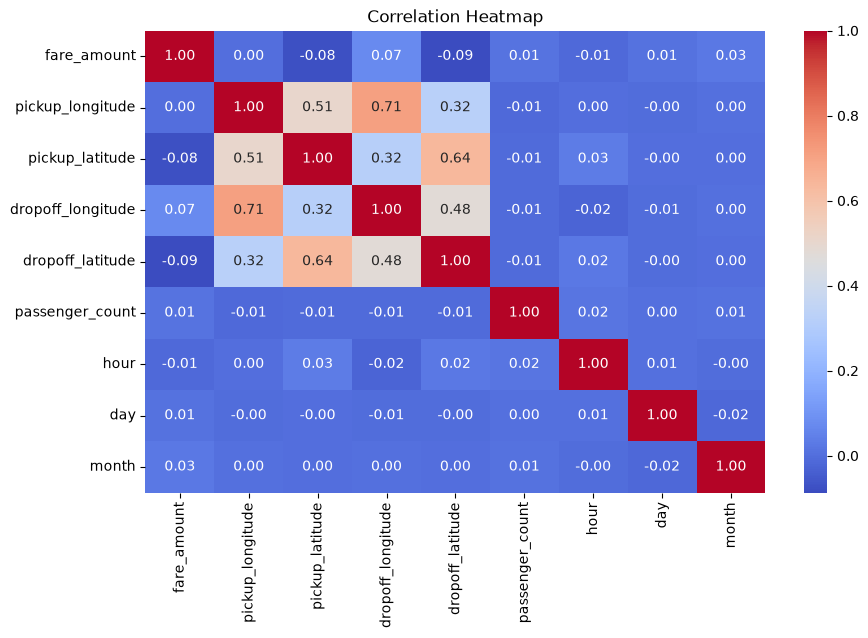

fare_amount          1.000000
dropoff_longitude    0.073951
month                0.026859
passenger_count      0.012437
day                  0.006977
pickup_longitude     0.001255
hour                -0.012952
pickup_latitude     -0.075714
dropoff_latitude    -0.086857
Name: fare_amount, dtype: float64


In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print(df.corr(numeric_only=True)["fare_amount"].sort_values(ascending=False))

## 8. Select features and target

The target is `fare_amount`. The remaining selected columns are used as model features.

In [9]:
features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "hour", "day", "month"
]
X = df[features]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142713, 8)
Testing data: (35679, 8)


## 9. Train Linear Regression

In [10]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

## 10. Train Random Forest Regression

In [11]:
rf = RandomForestRegressor(
    n_estimators=50, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

## 11. Evaluate both models

**R²** measures explained variance; **RMSE** and **MAE** measure prediction error. Lower RMSE/MAE is better, while higher R² is generally better.

In [12]:
def evaluate_model(name, actual, predicted):
    print(name)
    print("R2 Score:", round(r2_score(actual, predicted), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 3))
    print("MAE:", round(mean_absolute_error(actual, predicted), 3))
    print()

evaluate_model("Linear Regression", y_test, lr_pred)
evaluate_model("Random Forest", y_test, rf_pred)

Linear Regression
R2 Score: 0.032
RMSE: 4.075
MAE: 3.232

Random Forest
R2 Score: 0.731
RMSE: 2.146
MAE: 1.505



## 12. Predict fare for a sample ride

The sample coordinates and date/time features are illustrative. The prediction depends on the dataset and trained model.

In [13]:
sample_ride = pd.DataFrame([{
    "pickup_longitude": -73.985,
    "pickup_latitude": 40.758,
    "dropoff_longitude": -73.9855,
    "dropoff_latitude": 40.748,
    "passenger_count": 1,
    "hour": 14,
    "day": 15,
    "month": 10
}])

predicted_fare = rf.predict(sample_ride)
print("Predicted Uber fare: $", round(predicted_fare[0], 2))

Predicted Uber fare: $ 6.23


## Conclusion

The notebook preprocesses Uber trip data, explores feature correlations, trains Linear Regression and Random Forest regression models, evaluates their performance using R², RMSE, and MAE, and predicts a fare for a sample ride.

**Note:** Model scores can differ depending on the dataset, filtering, library versions, and runtime environment.